# Diagnostic multimodal - notebook
One notebook to test everything. Move working code into src/ later.

In [11]:
import os, time, random
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as error:
        print(error)

if gpus:
    print(f"GPU acceleration enabled: {len(gpus)} device(s)")
    for gpu in gpus:
        print(f"  {gpu}")
else:
    print("No GPU detected - training on CPU")

from sklearn.metrics import classification_report, confusion_matrix
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
from tensorflow.keras.callbacks import EarlyStopping ,ModelCheckpoint
from tensorflow.keras.models import load_model
from ultralytics import YOLO
import mlflow

2026/10/30 15:21:49 INFO mlflow.tracking.fluent: Autologging successfully enabled for sklearn.
2026/10/30 15:21:49 INFO mlflow.tracking.fluent: Autologging successfully enabled for keras.
2026/10/30 15:21:49 INFO mlflow.tracking.fluent: Autologging successfully enabled for tensorflow.


GPU acceleration enabled: 1 device(s)
  PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


# PART 1 - Classification (GoogLeNet)

> Keras has no InceptionV1 in keras.applications. Find pretrained GoogLeNet weights (Keras port or conversion from torchvision).

### Step 1

Charger les images, vérifier extensions et intégrité (try-except), écarter les fichiers invalides.

In [8]:


DATA_DIR = "./data/classification"
TRAIN_DIR = os.path.join(DATA_DIR, "Train")
VAL_DIR = os.path.join(DATA_DIR, "Val")

class_names = sorted(os.listdir(TRAIN_DIR))

VALID_EXTENSIONS = [".jpg", ".jpeg", ".png", ".bmp"]


def validate_image_dataset(split_dir, class_names, valid_extensions):
    valid_images = []
    invalid_images = []

    for class_name in class_names:
        folder_path = os.path.join(split_dir, class_name, "images")

        for file_name in os.listdir(folder_path):

            file_path = os.path.join(folder_path, file_name)

            if not os.path.isfile(file_path):
                continue

            extension = os.path.splitext(file_name)[1].lower()

            if extension not in valid_extensions:
                invalid_images.append(file_path)
                os.remove(file_path)
                continue

            try:
                with Image.open(file_path) as img:
                    img.load()

                valid_images.append(file_path)

            except Exception:
                invalid_images.append(file_path)
                os.remove(file_path)

    return valid_images, invalid_images




train_valid, train_invalid = validate_image_dataset(
    TRAIN_DIR, class_names, VALID_EXTENSIONS
)

val_valid, val_invalid = validate_image_dataset(
    VAL_DIR, class_names, VALID_EXTENSIONS
)


### Step 2

Explorer les classes (noms de dossiers), countplot, afficher un échantillon par classe.

Training valid images: 4737
Training invalid files: 0
Validation valid images: 512
Validation invalid files: 0
classes ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']


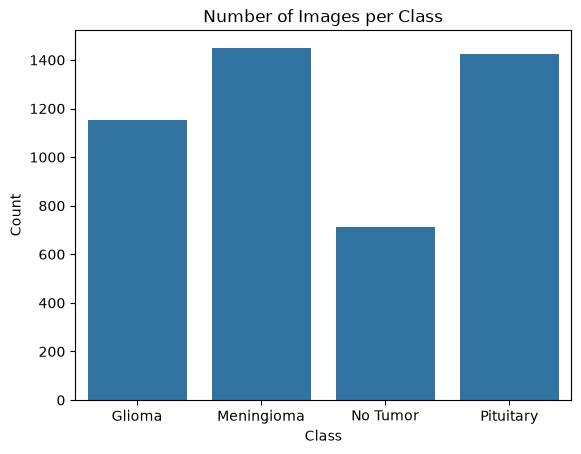

None

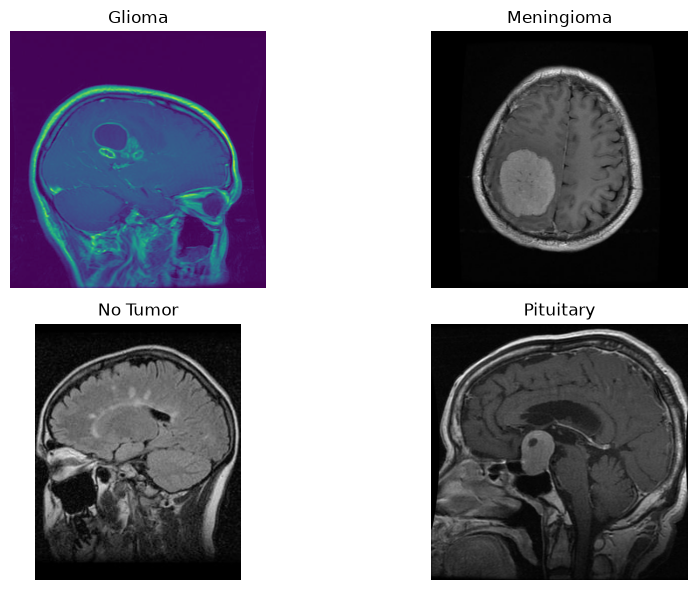

In [9]:

print("Training valid images:", len(train_valid))
print("Training invalid files:", len(train_invalid))

print("Validation valid images:", len(val_valid))
print("Validation invalid files:", len(val_invalid))


print("classes", os.listdir(TRAIN_DIR))

class_counts = {}

for class_name in class_names:
    count = 0
    for image_path in train_valid:
        if class_name in image_path:
            count += 1
    class_counts[class_name] = count
    
    df_counts = pd.DataFrame(list(class_counts.items()), columns=["Class", "Count"])
    
sns.barplot(x="Class", y="Count", data=df_counts)
plt.title("Number of Images per Class")
plt.xlabel("Class")
plt.ylabel("Count")
display(plt.show())

plt.figure(figsize=(10, 6))
for i,class_name in enumerate(class_names):
    image_path = random.choice([img_path for img_path in train_valid if class_name in img_path])
    image = Image.open(image_path)
    plt.subplot(2, 2, i + 1)
    plt.imshow(image)
    plt.axis('off')
    plt.title(class_name)
    
plt.tight_layout()
plt.show()

### Step 3

Répartir les images en trois ensembles : Train (70 %), Validation (15 %) et Test (15 %), puis compter et afficher le nombre d'images dans chaque ensemble.

In [10]:

X = train_valid + val_valid

def get_label_from_path(image_path):
    for class_name in class_names:
        if class_name in image_path:
            return class_name
    return None

def split_dataset(X):
    X_train, X_temp = train_test_split(
        X, test_size=0.3, random_state=42
    )

    X_val, X_test = train_test_split(
        X_temp, test_size=0.5, random_state=42
    )
    
    y_train = [get_label_from_path(path) for path in X_train]
    y_val = [get_label_from_path(path) for path in X_val]
    y_test = [get_label_from_path(path) for path in X_test]

    return X_train, X_val, X_test, y_train, y_val, y_test


X_train, X_val, X_test, y_train, y_val, y_test = split_dataset(X)

print('train images:', len(X_train))
print('validation images:', len(X_val))
print('test images:', len(X_test))

train images: 3674
validation images: 787
test images: 788


### Step 4

Appliquer des techniques d'augmentation des données (blur, noise, flip) uniquement sur les données d'entraînement, afin d'enrichir les échantillons et de réduire les déséquilibres entre les classes.

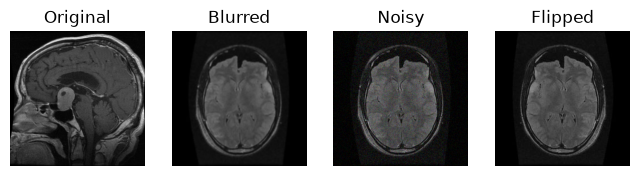

In [11]:
def augmentation(X_train):
    image_path = random.choice(X_train)
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    blurred_image = cv2.GaussianBlur(image, (3, 3), 0)
    noise = np.random.randint(-15, 16, image.shape)
    noise_image = np.clip(image.astype(np.int16) + noise, 0, 255).astype(np.uint8)
    flipped_image = cv2.flip(image, 1)
    plt.figure(figsize=(8, 4))
    return blurred_image,noise_image,flipped_image

blurred_image,noise_image,flipped_image = augmentation(X_train)

plt.subplot(1, 4, 1)
plt.imshow(image)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(blurred_image)
plt.title("Blurred")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(noise_image)
plt.title("Noisy")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(flipped_image)
plt.title("Flipped")
plt.axis("off")

plt.show()

### Step 5

Charger avec image_dataset_from_directory() (redimensionnement, batch, shuffle=True pour le train), puis normaliser selon le modèle.

In [12]:
def create_dataset_and_normalize(directory, shuffle=True):
    dataset = tf.keras.utils.image_dataset_from_directory(
        directory,
        image_size=(224, 224),
        batch_size=32,
        shuffle=shuffle
    )
    


    return dataset

train_dataset = create_dataset_and_normalize("./data/classification/Train", shuffle=True)
val_dataset = create_dataset_and_normalize("./data/classification/Val", shuffle=False)


Found 4737 files belonging to 4 classes.


I0000 00:00:1793370418.436906   96693 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5563 MB memory:  -> device: 0, name: NVIDIA RTX 2000 Ada Generation Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Found 512 files belonging to 4 classes.


### Step 6

Charger le modèle préentraîné GoogLeNet (InceptionV3), geler ses couches de base, remplacer sa tête de classification par une nouvelle adaptée au nombre de classes, puis entraîner uniquement cette dernière (Feature Extraction).

In [13]:
def create_model():
    base_model = tf.keras.applications.InceptionV3(weights="imagenet",include_top=False, input_shape=(224,224,3))
    base_model.trainable = False
    inputs = tf.keras.Input(shape=(224,224,3))
    x = tf.keras.layers.Rescaling(1./127.5, offset=-1)(inputs)
    x = base_model(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(128, activation="relu")(x)
    outputs = tf.keras.layers.Dense(
        4,
        activation="softmax"
    )(x)
    model = tf.keras.Model(inputs, outputs)
    return model
model = create_model()

model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 5, 5, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,065,572 (84.17 MB)

 Trainable params: 262,788 (1.00 MB)

 Non-trainable params: 21,802,784 (83.17 MB)

### Step 7

Déterminer les hyperparamètres d'entraînement : learning rate, fonction de perte (loss) et optimiseur (optimizer).

In [14]:
model = create_model()

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
early_stopping = EarlyStopping(
    monitor='val_loss', 
    patience=6, 
    restore_best_weights=True
)

checkpoint_callback = ModelCheckpoint(
    filepath="./brain_tumor_best.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)
callable = [early_stopping,checkpoint_callback]

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=25,
    callbacks=callable
)


Epoch 1/25


/root/tf-gpu/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
2026-10-30 14:27:06.169306: I external/local_xla/xla/service/service.cc:163] XLA service 0x7596d40576e0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-10-30 14:27:06.169352: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA RTX 2000 Ada Generation Laptop GPU, Compute Capability 8.9
2026-10-30 14:27:06.390104: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-10-30 14:27:07.965856: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 92400
2026

  2/149 ━━━━━━━━━━━━━━━━━━━━ 12s 85ms/step - accuracy: 0.2656 - loss: 2.0664 

I0000 00:00:1793370439.274458  105000 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step - accuracy: 0.7874 - loss: 0.5556
Epoch 1: val_loss improved from None to 0.42656, saving model to ./brain_tumor_best.keras

Epoch 1: finished saving model to ./brain_tumor_best.keras
149/149 ━━━━━━━━━━━━━━━━━━━━ 41s 162ms/step - accuracy: 0.7874 - loss: 0.5556 - val_accuracy: 0.8398 - val_loss: 0.4266
Epoch 2/25
148/149 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.8908 - loss: 0.3068
Epoch 2: val_loss improved from 0.42656 to 0.33000, saving model to ./brain_tumor_best.keras

Epoch 2: finished saving model to ./brain_tumor_best.keras
149/149 ━━━━━━━━━━━━━━━━━━━━ 8s 51ms/step - accuracy: 0.8909 - loss: 0.3067 - val_accuracy: 0.8867 - val_loss: 0.3300
Epoch 3/25
147/149 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.9190 - loss: 0.2254
Epoch 3: val_loss did not improve from 0.33000
149/149 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - accuracy: 0.9191 - loss: 0.2256 - val_accuracy: 0.8262 - val_loss: 0.4883
Epoch 4/25
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 3

### Step 8

Entraîner le modèle sur l'ensemble d'entraînement et suivre ses performances sur l'ensemble de validation.

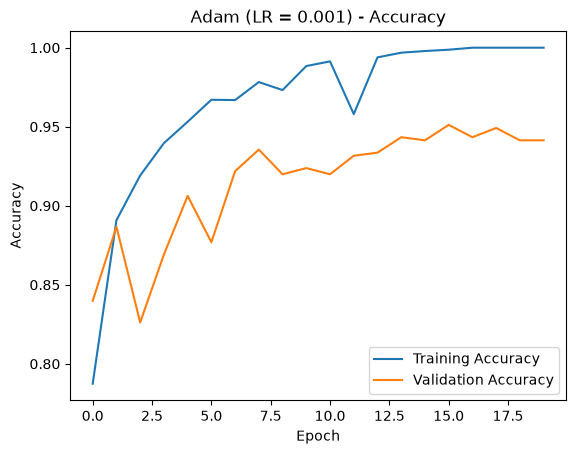

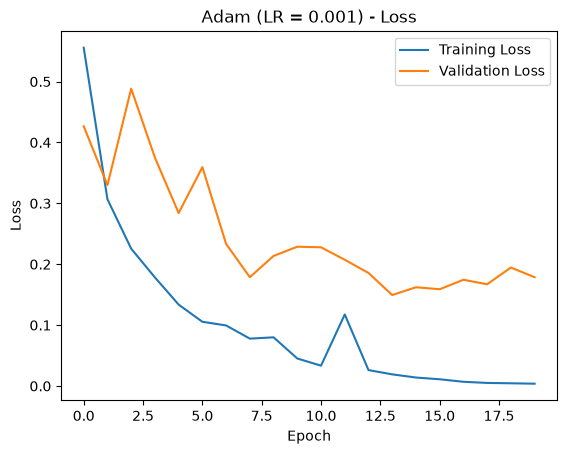

In [15]:

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Adam (LR = 0.001) - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Adam (LR = 0.001) - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

### Step 9

Évaluer le modèle : accuracy, précision (precision), rappel (recall) et F1-score.

In [16]:
y_true = np.concatenate([
    labels.numpy() for images, labels in val_dataset
])

y_pred_prob = model.predict(val_dataset)
y_pred = np.argmax(y_pred_prob, axis=1)

print("Accuracy:", accuracy_score(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=train_dataset.class_names
))


2026-10-30 14:30:32.708424: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


16/16 ━━━━━━━━━━━━━━━━━━━━ 11s 56ms/step
Accuracy: 0.943359375

Classification Report:
              precision    recall  f1-score   support

      Glioma       0.92      0.94      0.93       136
  Meningioma       0.91      0.91      0.91       140
    No Tumor       0.99      0.94      0.96       100
   Pituitary       0.96      0.99      0.97       136

    accuracy                           0.94       512
   macro avg       0.95      0.94      0.94       512
weighted avg       0.94      0.94      0.94       512



### Step 10

Analyser les résultats avec une matrice de confusion et comparer les performances sur les ensembles d'entraînement et de test.

2026-10-30 14:30:53.156952: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


149/149 ━━━━━━━━━━━━━━━━━━━━ 12s 78ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step


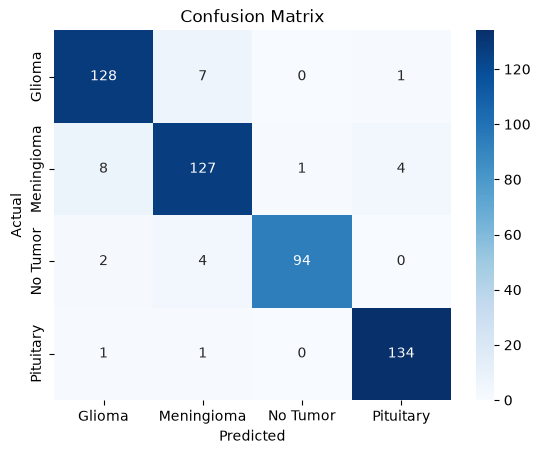

Train accuracy: 0.26599113362887905
Test accuracy: 0.943359375


In [17]:
y_train_true = np.concatenate([labels.numpy() for images, labels in train_dataset])
y_test_true = np.concatenate([labels.numpy() for images, labels in val_dataset])
y_train_pred = np.argmax(model.predict(train_dataset), axis=1)
y_test_pred = np.argmax(model.predict(val_dataset), axis=1)

matrix = confusion_matrix(y_test_true, y_test_pred)

sns.heatmap(
    matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

print("Train accuracy:", accuracy_score(y_train_true, y_train_pred))
print("Test accuracy:", accuracy_score(y_test_true, y_test_pred))

### Step 11

Dégeler les dernières couches du modèle préentraîné, poursuivre le fine-tuning avec un faible learning rate, réévaluer le modèle et comparer avec le modèle du Feature Extraction.

In [18]:
base_model = model.layers[2]
base_model.trainable = True

for layer in base_model.layers[:-20]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

fine_tune_history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=5
)

Epoch 1/5


/root/tf-gpu/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


149/149 ━━━━━━━━━━━━━━━━━━━━ 29s 111ms/step - accuracy: 0.9536 - loss: 0.1264 - val_accuracy: 0.9453 - val_loss: 0.1350
Epoch 2/5
149/149 ━━━━━━━━━━━━━━━━━━━━ 6s 42ms/step - accuracy: 0.9905 - loss: 0.0397 - val_accuracy: 0.9492 - val_loss: 0.1291
Epoch 3/5
149/149 ━━━━━━━━━━━━━━━━━━━━ 6s 43ms/step - accuracy: 0.9949 - loss: 0.0307 - val_accuracy: 0.9453 - val_loss: 0.1274
Epoch 4/5
149/149 ━━━━━━━━━━━━━━━━━━━━ 6s 42ms/step - accuracy: 0.9941 - loss: 0.0297 - val_accuracy: 0.9453 - val_loss: 0.1229
Epoch 5/5
149/149 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step - accuracy: 0.9954 - loss: 0.0265 - val_accuracy: 0.9473 - val_loss: 0.1311


### Step 12

Sauvegarder le modèle entraîné.

In [19]:
model.save("./brain_tumor_finetuned.keras")
print("Model saved successfully.")

Model saved successfully.


# PART 2 - Detection (YOLOv8)

### Step 1

Afficher un échantillon d'images avec leurs boîtes englobantes (bounding boxes) et les classes correspondantes.

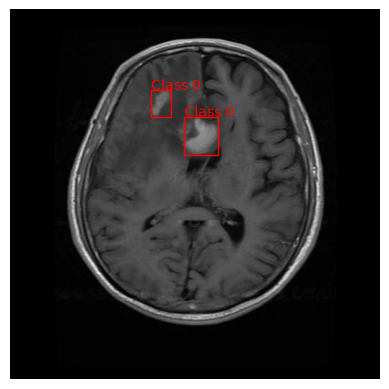

In [20]:
def show_image_with_labels(image_path, label_path):
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    height, width = image.shape[:2]

    plt.imshow(image)

    with open(label_path, "r") as file:
        for line in file:
            class_id, center_x, center_y, box_width, box_height = map(float, line.split())
            center_x = center_x * width
            center_y = center_y * height
            box_width = box_width * width
            box_height = box_height * height
            x = center_x - box_width / 2
            y = center_y - box_height / 2

            box = plt.Rectangle((x, y), box_width, box_height, fill=False, color="red")
            plt.gca().add_patch(box)
            plt.text(x, y, f"Class {int(class_id)}", color="red")

    plt.axis("off")
    plt.show()

image_path = "./data/classification/Train/Glioma/images/gg (3).jpg"
label_path = "./data/classification/Train/Glioma/labels/gg (3).txt"
show_image_with_labels(image_path, label_path)

### Step 2

Vérifier, pour chaque image, l'existence d'un fichier .txt correspondant dans le répertoire des annotations (comparer les noms de base des fichiers).

In [21]:
def check_labels(split_folder, class_names):
    missing_labels = []
    extra_labels = []

    for class_name in class_names:
        image_folder = os.path.join(split_folder, class_name, "images")
        label_folder = os.path.join(split_folder, class_name, "labels")

        image_names = {
            os.path.splitext(file_name)[0]
            for file_name in os.listdir(image_folder)
        }
        label_names = {
            os.path.splitext(file_name)[0]
            for file_name in os.listdir(label_folder)
        }

        missing_labels.extend(image_names - label_names)
        extra_labels.extend(label_names - image_names)

    return missing_labels, extra_labels

train_missing, train_extra = check_labels(TRAIN_DIR, class_names)
val_missing, val_extra = check_labels(VAL_DIR, class_names)

print("Train missing labels:", len(train_missing))
print("Train extra labels:", len(train_extra))
print("Validation missing labels:", len(val_missing))
print("Validation extra labels:", len(val_extra))

Train missing labels: 0
Train extra labels: 0
Validation missing labels: 2
Validation extra labels: 2


### Step 3

Organiser les données dans les dossiers images et labels, en respectant les ensembles train, valid et test.

In [22]:
detection_folder = "./data/detection"

for split in ["train", "valid", "test"]:
    os.makedirs(os.path.join(detection_folder, split, "images"), exist_ok=True)
    os.makedirs(os.path.join(detection_folder, split, "labels"), exist_ok=True)

print("Detection folders are ready.")

Detection folders are ready.


### Step 4

Séparer les données Train en train/validation et utiliser les données Val comme test.

In [23]:
import os
import shutil
from sklearn.model_selection import train_test_split

def clear_folder(folder):
    for file_name in os.listdir(folder):
        os.remove(os.path.join(folder, file_name))

def copy_pair(image_path, label_path, target_folder, class_name, image_name):
    new_name = class_name + "_" + image_name
    shutil.copy2(image_path, os.path.join(target_folder, "images", new_name))
    label_name = os.path.splitext(new_name)[0] + ".txt"
    shutil.copy2(label_path, os.path.join(target_folder, "labels", label_name))

for split in ["train", "valid", "test"]:
    clear_folder(os.path.join(detection_folder, split, "images"))
    clear_folder(os.path.join(detection_folder, split, "labels"))

train_count = 0
valid_count = 0
test_count = 0

for class_name in class_names:
    image_folder = os.path.join(TRAIN_DIR, class_name, "images")
    label_folder = os.path.join(TRAIN_DIR, class_name, "labels")
    pairs = []

    for image_name in os.listdir(image_folder):
        image_path = os.path.join(image_folder, image_name)
        label_path = os.path.join(label_folder, os.path.splitext(image_name)[0] + ".txt")
        if os.path.exists(label_path):
            pairs.append((image_path, label_path, image_name))

    train_pairs, valid_pairs = train_test_split(
        pairs, test_size=0.15, random_state=42
    )

    for image_path, label_path, image_name in train_pairs:
        copy_pair(image_path, label_path, os.path.join(detection_folder, "train"), class_name, image_name)
        train_count += 1

    for image_path, label_path, image_name in valid_pairs:
        copy_pair(image_path, label_path, os.path.join(detection_folder, "valid"), class_name, image_name)
        valid_count += 1

for class_name in class_names:
    image_folder = os.path.join(VAL_DIR, class_name, "images")
    label_folder = os.path.join(VAL_DIR, class_name, "labels")

    for image_name in os.listdir(image_folder):
        image_path = os.path.join(image_folder, image_name)
        label_path = os.path.join(label_folder, os.path.splitext(image_name)[0] + ".txt")
        if os.path.exists(label_path):
            copy_pair(image_path, label_path, os.path.join(detection_folder, "test"), class_name, image_name)
            test_count += 1

print("Training pairs copied:", train_count)
print("Validation pairs copied:", valid_count)
print("Test pairs copied:", test_count)

Training pairs copied: 4025
Validation pairs copied: 712
Test pairs copied: 510


### Step 5

Écarter les images sans annotation et les fichiers d'annotation sans image associée.

In [24]:
def remove_unmatched_files(split_folder):
    image_folder = os.path.join(split_folder, "images")
    label_folder = os.path.join(split_folder, "labels")

    image_names = {
        os.path.splitext(name)[0] for name in os.listdir(image_folder)
    }
    label_names = {
        os.path.splitext(name)[0] for name in os.listdir(label_folder)
    }

    for name in image_names - label_names:
        os.remove(os.path.join(image_folder, name + ".jpg"))

    for name in label_names - image_names:
        os.remove(os.path.join(label_folder, name + ".txt"))

remove_unmatched_files(os.path.join(detection_folder, "train"))
remove_unmatched_files(os.path.join(detection_folder, "valid"))
print("Unmatched files removed.")

Unmatched files removed.


### Step 6

Vérifier la validité du format des annotations YOLO et la cohérence des classes.

In [25]:
def check_labels_format(split_folder):
    invalid_labels = []
    class_ids = set()

    for file_name in os.listdir(os.path.join(split_folder, "labels")):
        label_path = os.path.join(split_folder, "labels", file_name)

        with open(label_path, "r") as file:
            for line_number, line in enumerate(file, start=1):
                values = line.split()

                if len(values) != 5:
                    invalid_labels.append((file_name, line_number))
                    continue

                class_id, center_x, center_y, box_width, box_height = map(float, values)
                class_ids.add(int(class_id))

                if (
                    class_id != int(class_id)
                    or class_id < 0
                    or not 0 <= center_x <= 1
                    or not 0 <= center_y <= 1
                    or not 0 < box_width <= 1
                    or not 0 < box_height <= 1
                ):
                    invalid_labels.append((file_name, line_number))

    return invalid_labels, class_ids

train_invalid, train_classes = check_labels_format(
    os.path.join(detection_folder, "train")
)
valid_invalid, valid_classes = check_labels_format(
    os.path.join(detection_folder, "valid")
)

print("Invalid train labels:", len(train_invalid))
print("Invalid validation labels:", len(valid_invalid))
print("Train class IDs:", sorted(train_classes))
print("Validation class IDs:", sorted(valid_classes))

Invalid train labels: 0
Invalid validation labels: 0
Train class IDs: [0, 1, 2, 3]
Validation class IDs: [0, 1, 2, 3]


### Step 7

Compter les images et les fichiers d'annotation dans chaque ensemble.

In [26]:
def count_files(folder):
    images = len(os.listdir(os.path.join(folder, "images")))
    labels = len(os.listdir(os.path.join(folder, "labels")))
    return images, labels

for split in ["train", "valid", "test"]:
    images, labels = count_files(os.path.join(detection_folder, split))
    print(split, "images:", images, "labels:", labels)

train images: 4025 labels: 4025
valid images: 712 labels: 712
test images: 510 labels: 510


### Step 8

Créer un fichier data.yaml (chemins train/val/test, nombre de classes, noms des classes).

In [27]:
data_yaml = """path: ./data/detection
train: train/images
val: valid/images
test: test/images
nc: 4
names: [Glioma, Meningioma, No_Tumor, Pituitary]
"""

with open("./data/detection/data.yaml", "w") as file:
    file.write(data_yaml)

print("data.yaml created.")

data.yaml created.


### Step 9

Définir les paramètres d'augmentation des données dans la configuration d'entraînement de YOLOv8.

In [1]:
augmentation = {
    "degrees": 5.0,
    "translate": 0.05,
    "scale": 0.10,
    "fliplr": 0.0,
    "flipud": 0.0,
    "mosaic": 0.0,
    "mixup": 0.0,
    "hsv_h": 0.0,
    "hsv_s": 0.0,
    "hsv_v": 0.05
}

print("Augmentation settings:", augmentation)

Augmentation settings: {'degrees': 5.0, 'translate': 0.05, 'scale': 0.1, 'fliplr': 0.0, 'flipud': 0.0, 'mosaic': 0.0, 'mixup': 0.0, 'hsv_h': 0.0, 'hsv_s': 0.0, 'hsv_v': 0.05}


### Step 10

Entraîner le modèle YOLOv8 avec des hyperparamètres adaptés au dataset et aux ressources disponibles.

In [6]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

results = model.train(
    data="./data/detection/data.yaml",
    epochs=20,
    imgsz=512,
    batch=32,
    workers=0,
    lr0=0.001,
    patience=15,
    device=0,
    project="./runs/detection",
    name="brain_tumor_fast",
    degrees=augmentation["degrees"],
    fliplr=augmentation["fliplr"],
    flipud=augmentation["flipud"],
    scale=augmentation["scale"],
    translate=augmentation["translate"],
    mosaic=augmentation["mosaic"]
)

New https://pypi.org/project/ultralytics/8.4.193 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.191 🚀 Python-3.13.17 torch-2.14.1+cu130 CUDA:0 (NVIDIA RTX 2000 Ada Generation Laptop GPU, 8188MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=./data/detection/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=tr

### Step 11

Évaluer : précision, rappel, mAP@0.5 et mAP@0.5:0.95.

In [7]:
validation_metrics = model.val(
    data="./data/detection/data.yaml",
    split="val",
    device=0
)

print("Precision:", validation_metrics.box.mp)
print("Recall:", validation_metrics.box.mr)
print("mAP@0.5:", validation_metrics.box.map50)
print("mAP@0.5:0.95:", validation_metrics.box.map)

Ultralytics 8.4.191 🚀 Python-3.13.17 torch-2.14.1+cu130 CUDA:0 (NVIDIA RTX 2000 Ada Generation Laptop GPU, 8188MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 1.5±0.3 ms, read: 9.2±2.5 MB/s, size: 23.2 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /mnt/c/Users/medga/OneDrive/Documents/youcode/Diagnostic-multimodal/data/detection/valid/labels.cache... 712 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 712/712 175.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 45/45 7.2it/s 6.3s0.1s
                   all        712        809      0.926      0.928      0.961      0.729
                Glioma        174        210      0.874      0.843        0.9      0.643
            Meningioma        216        226       0.96      0

### Step 12

Analyser les résultats et vérifier la généralisation du modèle sur l'ensemble de test.

In [8]:
import os

test_images = os.listdir("./data/detection/test/images")
test_labels = os.listdir("./data/detection/test/labels")

test_metrics = model.val(
    data="./data/detection/data.yaml",
    split="test",
    device=0
)
print("Test precision:", test_metrics.box.mp)
print("Test recall:", test_metrics.box.mr)
print("Test mAP@0.5:", test_metrics.box.map50)
print("Test mAP@0.5:0.95:", test_metrics.box.map)

Ultralytics 8.4.191 🚀 Python-3.13.17 torch-2.14.1+cu130 CUDA:0 (NVIDIA RTX 2000 Ada Generation Laptop GPU, 8188MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 2.1±0.6 ms, read: 2.6±0.7 MB/s, size: 30.1 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /mnt/c/Users/medga/OneDrive/Documents/youcode/Diagnostic-multimodal/data/detection/test/labels.cache... 510 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 510/510 112.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 6.6it/s 4.9s0.2s
                   all        510        554      0.944      0.929      0.951      0.729
                Glioma        135        153      0.888      0.883      0.893      0.664
            Meningioma        140        142      0.986      0.

### Step 13

Sauvegarder le modèle entraîné et les artefacts nécessaires à son utilisation.

In [9]:
import shutil

best_model_path = os.path.join(results.save_dir, "weights", "best.pt")
saved_model_path = "./data/detection/brain_tumor_yolo_best.pt"

shutil.copy2(best_model_path, saved_model_path)
shutil.copy2("./data/detection/data.yaml", "./data/detection/brain_tumor_data.yaml")

print("Model saved to:", saved_model_path)

Model saved to: ./data/detection/brain_tumor_yolo_best.pt


testing the model


image 1/1 /mnt/c/Users/medga/OneDrive/Documents/youcode/Diagnostic-multimodal/data/detection/test/meningiome2.jpg: 512x512 1 Meningioma, 18.4ms
Speed: 3.4ms preprocess, 18.4ms inference, 3.3ms postprocess per image at shape (1, 3, 512, 512)
Results saved to /mnt/c/Users/medga/OneDrive/Documents/youcode/Diagnostic-multimodal/runs/detect/predict-9


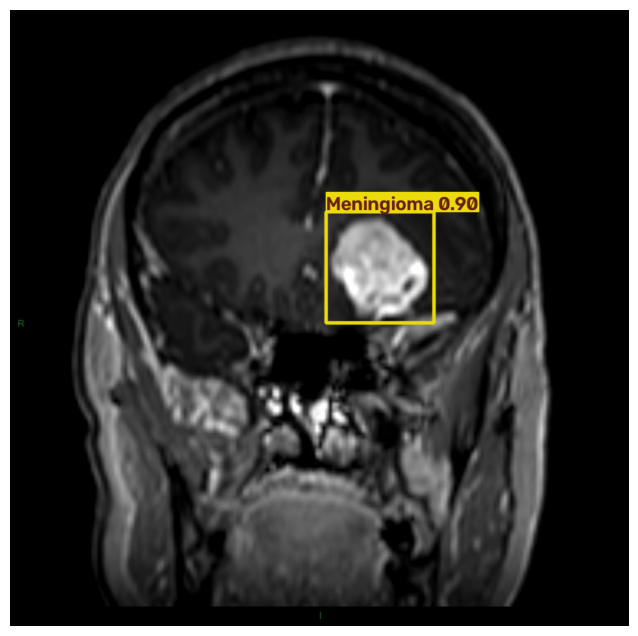

Prediction: Meningioma
Confidence: 89.72 %


In [12]:
models = YOLO("./data/detection/brain_tumor_yolo_best.pt")




image_path = "./data/detection/test/meningiome2.jpg"

resultss = models.predict(
    source=image_path,
    conf=0.25,
    save=True
)

result = resultss[0]

plt.figure(figsize=(8, 8))
plt.imshow(result.plot())
plt.axis("off")
plt.show()


for box in result.boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    class_name = models.names[class_id]

    print("Prediction:", class_name)
    print("Confidence:", round(confidence * 100, 2), "%")

# PART 3 - MLflow

> Start the MLflow UI in another terminal with: mlflow ui

### Step 1

Configurer une expérience MLflow pour suivre les entraînements.

In [13]:


experiment_name = "brain_tumor_models"

mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment(experiment_name)

print("MLflow is ready.")
print("Experiment:", experiment_name)
print("Database: mlflow.db")

MLflow is ready.
Experiment: brain_tumor_models
Database: mlflow.db


### Step 2

Enregistrer les hyperparamètres utilisés, les métriques obtenues et les artefacts pertinents.

In [14]:

with mlflow.start_run(run_name="brain_tumor_experiment"):

    mlflow.log_params({
        "classification_model": "InceptionV3",
        "detection_model": "YOLOv8n",
        "image_size": 224,
        "batch_size": 32,
        "classification_epochs": 25,
        "learning_rate": 0.001,
        "detection_image_size": 320,
        "detection_epochs": 5
    })

    if "history" in globals():
        mlflow.log_metrics({
            "classification_accuracy": float(history.history["accuracy"][-1]),
            "classification_validation_accuracy": float(
                history.history["val_accuracy"][-1]
            ),
            "classification_loss": float(history.history["loss"][-1]),
            "classification_validation_loss": float(
                history.history["val_loss"][-1]
            )
        })

    if "validation_metrics" in globals():
        mlflow.log_metrics({
            "detection_validation_precision": float(validation_metrics.box.mp),
            "detection_validation_recall": float(validation_metrics.box.mr),
            "detection_validation_map50": float(validation_metrics.box.map50),
            "detection_validation_map50_95": float(validation_metrics.box.map)
        })

    if "test_metrics" in globals():
        mlflow.log_metrics({
            "detection_test_precision": float(test_metrics.box.mp),
            "detection_test_recall": float(test_metrics.box.mr),
            "detection_test_map50": float(test_metrics.box.map50),
            "detection_test_map50_95": float(test_metrics.box.map)
        })

    files_to_save = [
        "./brain_tumor_best.keras",
        "./brain_tumor_finetuned.keras",
        "./data/detection/brain_tumor_yolo_best.pt",
        "./data/detection/data.yaml"
    ]

    for file_path in files_to_save:
        if os.path.exists(file_path):
            mlflow.log_artifact(file_path)

    print("Parameters, metrics, and artifacts saved.")
    print("Run ID:", mlflow.active_run().info.run_id)

Parameters, metrics, and artifacts saved.
Run ID: deb632a65a8a4a00afdc4d57fad34c90


### Step 3

Comparer plusieurs expériences afin d'identifier la configuration la plus performante.

In [15]:

experiment_name = "brain_tumor_models"

experiment = mlflow.get_experiment_by_name(experiment_name)

runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    order_by=["metrics.detection_validation_map50 DESC"]
)

columns = [
    "run_id",
    "status",
    "metrics.classification_accuracy",
    "metrics.classification_validation_accuracy",
    "metrics.detection_validation_precision",
    "metrics.detection_validation_recall",
    "metrics.detection_validation_map50",
    "metrics.detection_validation_map50_95"
]

available_columns = [column for column in columns if column in runs.columns]

comparison = runs[available_columns]

display(comparison)

,run_id,status,metrics.detection_validation_precision,metrics.detection_validation_recall,metrics.detection_validation_map50,metrics.detection_validation_map50_95
0,deb632a65a8a4a00afdc4d57fad34c90,FINISHED,0.926489,0.928387,0.961498,0.728626
1,57b8bac6a53b451f9ba89f79edc7d498,FINISHED,NaN,NaN,NaN,NaN


### Step 4

Enregistrer le modèle retenu et conserver les informations nécessaires à son identification et sa réutilisation.

In [16]:

best_run_id = comparison.iloc[0]["run_id"]

model_files = [
    "./brain_tumor_best.keras",
    "./brain_tumor_finetuned.keras",
    "./data/detection/brain_tumor_yolo_best.pt",
    "./data/detection/data.yaml"
]

with mlflow.start_run(run_id=best_run_id):
    mlflow.set_tag("selected_model", "best_model")
    mlflow.set_tag("selection_metric", "detection_validation_map50")

    for file_path in model_files:
        if os.path.exists(file_path):
            mlflow.log_artifact(file_path)

print("Best run saved.")
print("Best run ID:", best_run_id)

Best run saved.
Best run ID: deb632a65a8a4a00afdc4d57fad34c90


# Next
Airflow, FastAPI and Streamlit have their own files: airflow/dag_pipeline.py, api/main.py, app/streamlit_app.py